In [55]:
import numpy as np 
import pandas as pd

In [56]:
df = pd.read_csv("powerplant_data.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [57]:
from sklearn.model_selection import train_test_split
X = df.drop("PE" , axis = 1)
y = df["PE"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)


In [58]:
X.head()

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


In [59]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [60]:
X_train_scaled 

array([[ 0.01845156,  0.84137636,  0.49926379,  0.09294124],
       [-1.29179451, -0.98482991,  3.35699973, -0.36102302],
       [-0.75322711, -1.2134986 ,  0.43846089, -0.3004026 ],
       ...,
       [-0.21867886, -0.83709894,  0.36076831, -0.84874182],
       [ 0.95089661,  1.13840991, -0.42460239, -0.46641988],
       [-1.77275395, -1.19228191,  1.91462001,  0.91131686]],
      shape=(6410, 4))

In [61]:
import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled , dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype = torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled , dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype = torch.float32).view(-1,1)

In [62]:
type(X_train_scaled)

numpy.ndarray

In [63]:
type(X_test_scaled)

numpy.ndarray

In [64]:
from torch.utils.data import TensorDataset , DataLoader
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [65]:
train_loader = DataLoader(train_dataset , batch_size = 32 , shuffle = True)
test_loader = DataLoader(test_dataset , batch_size = 32 )

## DEEP LEARNING

In [66]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN , self).__init__()

        self.model = nn.Sequential(
               #1st hidden layer
               nn.Linear(X_train.shape[1], 6 ),
               nn.ReLU(),
    
               #2nd hidden layer
    
               nn.Linear(6, 6 ),
               nn.ReLU(),
    
               #output
               nn.Linear(6, 1 )
    
            
        )
    def forward(self , x):
        return self.model(x)


In [67]:
import torch.optim as optim

model = ANN()
# loss , optimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [68]:
epochs = 100

train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(epochs):
    model.train()
    loss_runner = 0.0

    for xb, yb in train_loader:
        # xb is feature 1 and labels of batch is yb
        optimizer.zero_grad()
        outputs = model(xb)  # forward prob
        loss = crietrion(outputs, yb)
        loss.backward()
        optimizer.step()  # update params

        loss_runner += loss.item()  # loss is tensor ==> py float

    epoch_train_loss = loss_runner / len(train_loader)
    train_losses.append(epoch_train_loss)
    model.eval()
    # validation
    val_loss_runner = 0.0

    with torch.no_grad():  # no gradient calculate
        for xb, yb in test_loader:
            # xb is feature 1 and labels of batch is yb

            outputs = model(xb)  # forward prob
            loss = crietrion(outputs, yb)

            val_loss_runner += loss.item()  # loss is tensor ==> py float

    epoch_val_loss = val_loss_runner / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch is ${epoch+1}/{epochs} ===. train loss = ${epoch_train_loss} & val_loss = ${epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt")

epoch is $1/100 ===. train loss = $205728.45708955225 & val_loss = $204530.0550820707
epoch is $2/100 ===. train loss = $199882.85758706467 & val_loss = $192438.19886363635
epoch is $3/100 ===. train loss = $176950.91052549751 & val_loss = $157283.703125
epoch is $4/100 ===. train loss = $131625.62733208956 & val_loss = $104471.51838699495
epoch is $5/100 ===. train loss = $79067.53097792288 & val_loss = $56661.55129419192
epoch is $6/100 ===. train loss = $41935.623853389305 & val_loss = $31323.29237689394
epoch is $7/100 ===. train loss = $26112.79246346393 & val_loss = $22757.304776278408
epoch is $8/100 ===. train loss = $20680.468944340795 & val_loss = $19038.118499447603
epoch is $9/100 ===. train loss = $17532.443160175684 & val_loss = $16097.785471906565
epoch is $10/100 ===. train loss = $14740.411577367071 & val_loss = $13358.692797111742
epoch is $11/100 ===. train loss = $12033.656514789334 & val_loss = $10748.186232441603
epoch is $12/100 ===. train loss = $9548.9868722792

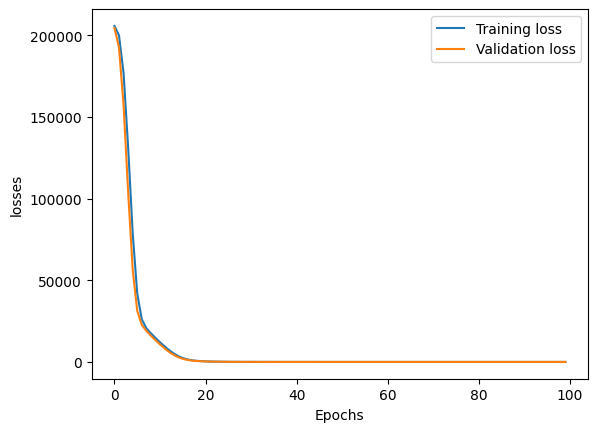

In [69]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
"Training_loss" : train_losses,
"Validation_losses" :val_losses
})

plt.plot(loss_df["Training_loss"] , label = "Training loss")
plt.plot(loss_df["Validation_losses"] , label = "Validation loss")

plt.xlabel("Epochs")
plt.ylabel("losses")

plt.legend()

In [70]:
#load best_model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [74]:
# evalute model
model.eval()

with torch.no_grad():  # no gradient calculate
        train_pred = model(X_train_tensor)
        test_pred = model(X_test_tensor)

        train_mse_loss =  crietrion(train_pred, y_train_tensor)
        test_mse_loss =  crietrion(test_pred, y_test_tensor)

print("Training MSE : ", train_mse_loss )
print("Test MSE : ", test_mse_loss )

Training MSE :  tensor(20.0096)
Test MSE :  tensor(18.8526)


In [76]:
from sklearn.metrics import r2_score
print("r2_score" , r2_score(y_test,test_pred) )

r2_score 0.9349530056542705


In [80]:
predicted_df = pd.DataFrame(test_pred.numpy() , columns = ["Predicted values"])
actual_df = pd.DataFrame(y_test.values , columns = ["actual values"])

pd.concat([predicted_df , actual_df] , axis = 1)

,Predicted values,actual values
0,435.139435,433.27
1,436.673248,438.16
2,461.573517,458.42
3,476.701752,480.82
4,435.146301,441.41
...,...,...
3153,466.779388,468.45
3154,483.880859,485.24
3155,479.832306,482.83
3156,475.398956,479.14
